In [1]:
from google.colab import files
import pandas as pd

uploaded = files.upload()

Saving diabetes_data_upload.csv to diabetes_data_upload.csv


In [2]:
import pandas as pd

# Read uploaded CSV
filename = list(uploaded.keys())[0]

df = pd.read_csv(filename)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (520, 17)


,Age,Gender,Polyuria,Polydipsia,sudden weight loss,weakness,Polyphagia,Genital thrush,visual blurring,Itching,Irritability,delayed healing,partial paresis,muscle stiffness,Alopecia,Obesity,class
0,40,Male,No,Yes,No,Yes,No,No,No,Yes,No,Yes,No,Yes,Yes,Yes,Positive
1,58,Male,No,No,No,Yes,No,No,Yes,No,No,No,Yes,No,Yes,No,Positive
2,41,Male,Yes,No,No,Yes,Yes,No,No,Yes,No,Yes,No,Yes,Yes,No,Positive
3,45,Male,No,No,Yes,Yes,Yes,Yes,No,Yes,No,Yes,No,No,No,No,Positive
4,60,Male,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Positive


In [3]:
# View all column names
print("Column names:")
print(df.columns.tolist())

# Dataset information
print("\nDataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:")
print(df.duplicated().sum())

# Check target distribution
print("\nTarget Distribution:")
print(df["class"].value_counts())

Column names:
['Age', 'Gender', 'Polyuria', 'Polydipsia', 'sudden weight loss', 'weakness', 'Polyphagia', 'Genital thrush', 'visual blurring', 'Itching', 'Irritability', 'delayed healing', 'partial paresis', 'muscle stiffness', 'Alopecia', 'Obesity', 'class']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 520 entries, 0 to 519
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Age                 520 non-null    int64 
 1   Gender              520 non-null    object
 2   Polyuria            520 non-null    object
 3   Polydipsia          520 non-null    object
 4   sudden weight loss  520 non-null    object
 5   weakness            520 non-null    object
 6   Polyphagia          520 non-null    object
 7   Genital thrush      520 non-null    object
 8   visual blurring     520 non-null    object
 9   Itching             520 non-null    object
 10  Irritability        520 non-null

In [4]:
# Create a copy
df_clean = df.copy()

# Remove duplicate records
df_clean = df_clean.drop_duplicates()

# Remove extra spaces from column names
df_clean.columns = df_clean.columns.str.strip()

# Remove extra spaces from text values
for col in df_clean.select_dtypes(include="object").columns:
    df_clean[col] = df_clean[col].str.strip()

print("Preprocessing completed!")
print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)

display(df_clean.head())# Create a copy
df_clean = df.copy()

# Remove duplicate records
df_clean = df_clean.drop_duplicates()

# Remove extra spaces from column names
df_clean.columns = df_clean.columns.str.strip()

# Remove extra spaces from text values
for col in df_clean.select_dtypes(include="object").columns:
    df_clean[col] = df_clean[col].str.strip()

print("Preprocessing completed!")
print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)

display(df_clean.head())

Preprocessing completed!
Original shape: (520, 17)
Cleaned shape: (251, 17)


,Age,Gender,Polyuria,Polydipsia,sudden weight loss,weakness,Polyphagia,Genital thrush,visual blurring,Itching,Irritability,delayed healing,partial paresis,muscle stiffness,Alopecia,Obesity,class
0,40,Male,No,Yes,No,Yes,No,No,No,Yes,No,Yes,No,Yes,Yes,Yes,Positive
1,58,Male,No,No,No,Yes,No,No,Yes,No,No,No,Yes,No,Yes,No,Positive
2,41,Male,Yes,No,No,Yes,Yes,No,No,Yes,No,Yes,No,Yes,Yes,No,Positive
3,45,Male,No,No,Yes,Yes,Yes,Yes,No,Yes,No,Yes,No,No,No,No,Positive
4,60,Male,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Positive


Preprocessing completed!
Original shape: (520, 17)
Cleaned shape: (251, 17)


,Age,Gender,Polyuria,Polydipsia,sudden weight loss,weakness,Polyphagia,Genital thrush,visual blurring,Itching,Irritability,delayed healing,partial paresis,muscle stiffness,Alopecia,Obesity,class
0,40,Male,No,Yes,No,Yes,No,No,No,Yes,No,Yes,No,Yes,Yes,Yes,Positive
1,58,Male,No,No,No,Yes,No,No,Yes,No,No,No,Yes,No,Yes,No,Positive
2,41,Male,Yes,No,No,Yes,Yes,No,No,Yes,No,Yes,No,Yes,Yes,No,Positive
3,45,Male,No,No,Yes,Yes,Yes,Yes,No,Yes,No,Yes,No,No,No,No,Positive
4,60,Male,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Positive


In [5]:
# Convert categorical columns into numeric form
df_encoded = pd.get_dummies(
    df_clean,
    columns=["Gender"],
    drop_first=True
)

# Convert Yes/No columns into 1/0
for col in df_encoded.columns:
    if col != "class" and df_encoded[col].dtype == "object":
        df_encoded[col] = df_encoded[col].map({
            "Yes": 1,
            "No": 0
        })

# Convert target variable
df_encoded["class"] = df_encoded["class"].map({
    "Positive": 1,
    "Negative": 0
})

print("Categorical encoding completed!")
display(df_encoded.head())

Categorical encoding completed!


,Age,Polyuria,Polydipsia,sudden weight loss,weakness,Polyphagia,Genital thrush,visual blurring,Itching,Irritability,delayed healing,partial paresis,muscle stiffness,Alopecia,Obesity,class,Gender_Male
0,40,0,1,0,1,0,0,0,1,0,1,0,1,1,1,1,True
1,58,0,0,0,1,0,0,1,0,0,0,1,0,1,0,1,True
2,41,1,0,0,1,1,0,0,1,0,1,0,1,1,0,1,True
3,45,0,0,1,1,1,1,0,1,0,1,0,0,0,0,1,True
4,60,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,True


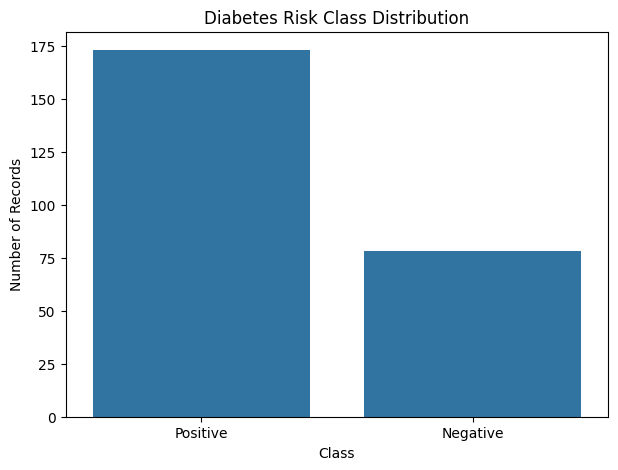

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df_clean,
    x="class"
)

plt.title("Diabetes Risk Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Records")

plt.show()

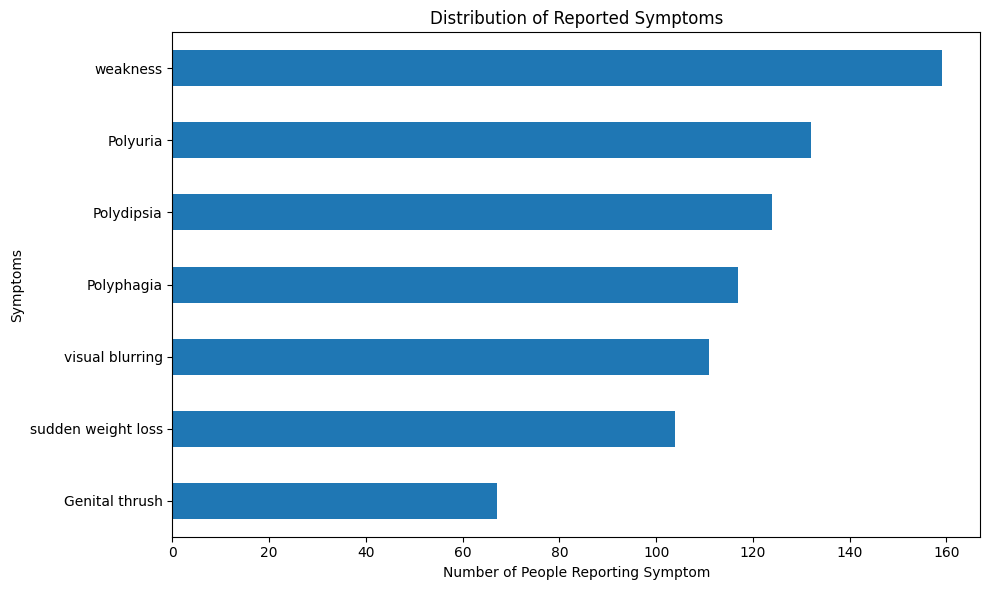

In [7]:
symptoms = [
    "Polyuria",
    "Polydipsia",
    "sudden weight loss",
    "weakness",
    "Polyphagia",
    "Genital thrush",
    "visual blurring"
]

plt.figure(figsize=(10, 6))

symptom_counts = df_clean[symptoms].apply(
    lambda col: (col == "Yes").sum()
)

symptom_counts.sort_values().plot(kind="barh")

plt.title("Distribution of Reported Symptoms")
plt.xlabel("Number of People Reporting Symptom")
plt.ylabel("Symptoms")

plt.tight_layout()
plt.show()

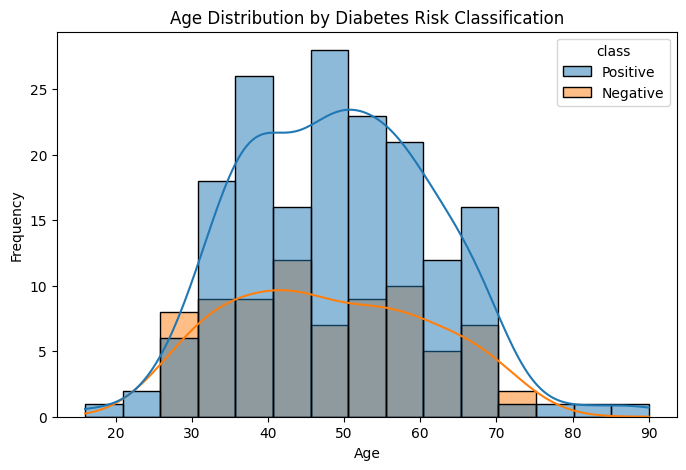

In [8]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_clean,
    x="Age",
    hue="class",
    bins=15,
    kde=True
)

plt.title("Age Distribution by Diabetes Risk Classification")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()

In [9]:
from sklearn.model_selection import train_test_split

# Separate features and target
X = df_encoded.drop("class", axis=1)
y = df_encoded["class"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (200, 16)
Testing data: (51, 16)


In [10]:
from sklearn.linear_model import LogisticRegression

# Create model
model = LogisticRegression(max_iter=1000)

# Train the model
model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [11]:
# Predict test data
y_pred = model.predict(X_test)

print("Predictions completed!")

print("Actual values:")
print(y_test.head(10).values)

print("\nPredicted values:")
print(y_pred[:10])

Predictions completed!
Actual values:
[0 1 0 1 1 0 0 1 0 1]

Predicted values:
[0 1 1 1 0 0 0 1 0 1]


In [12]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("===== MODEL PERFORMANCE =====")
print("Accuracy :", round(accuracy * 100, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Recall   :", round(recall * 100, 2), "%")
print("F1 Score :", round(f1 * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

===== MODEL PERFORMANCE =====
Accuracy : 82.35 %
Precision: 93.33 %
Recall   : 80.0 %
F1 Score : 86.15 %

Classification Report:
              precision    recall  f1-score   support

           0       0.67      0.88      0.76        16
           1       0.93      0.80      0.86        35

    accuracy                           0.82        51
   macro avg       0.80      0.84      0.81        51
weighted avg       0.85      0.82      0.83        51



In [13]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

tn, fp, fn, tp = cm.ravel()

print("\nTrue Negative:", tn)
print("False Positive:", fp)
print("False Negative:", fn)
print("True Positive:", tp)

Confusion Matrix:
[[14  2]
 [ 7 28]]

True Negative: 14
False Positive: 2
False Negative: 7
True Positive: 28


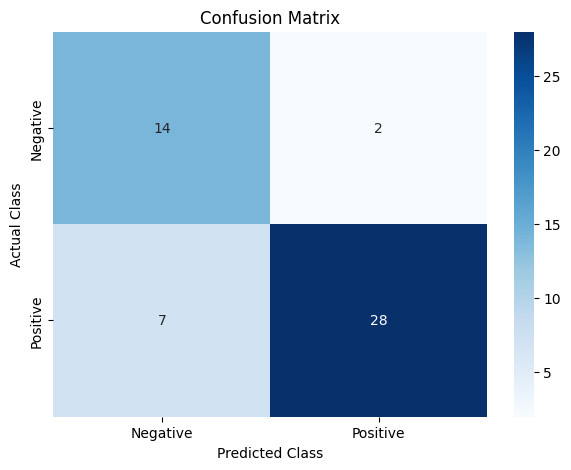

In [14]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.show()

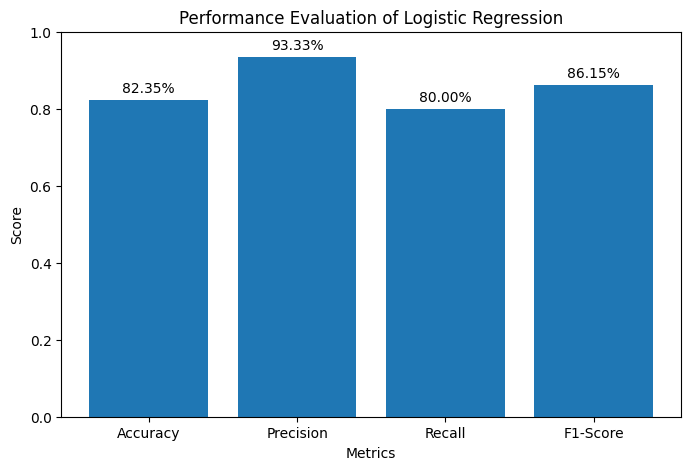

In [15]:
metrics = {
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1-Score": f1
}

plt.figure(figsize=(8, 5))

bars = plt.bar(
    metrics.keys(),
    metrics.values()
)

plt.ylim(0, 1)

plt.title("Performance Evaluation of Logistic Regression")
plt.ylabel("Score")
plt.xlabel("Metrics")

for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 0.02,
        f"{height:.2%}",
        ha="center"
    )

plt.show()

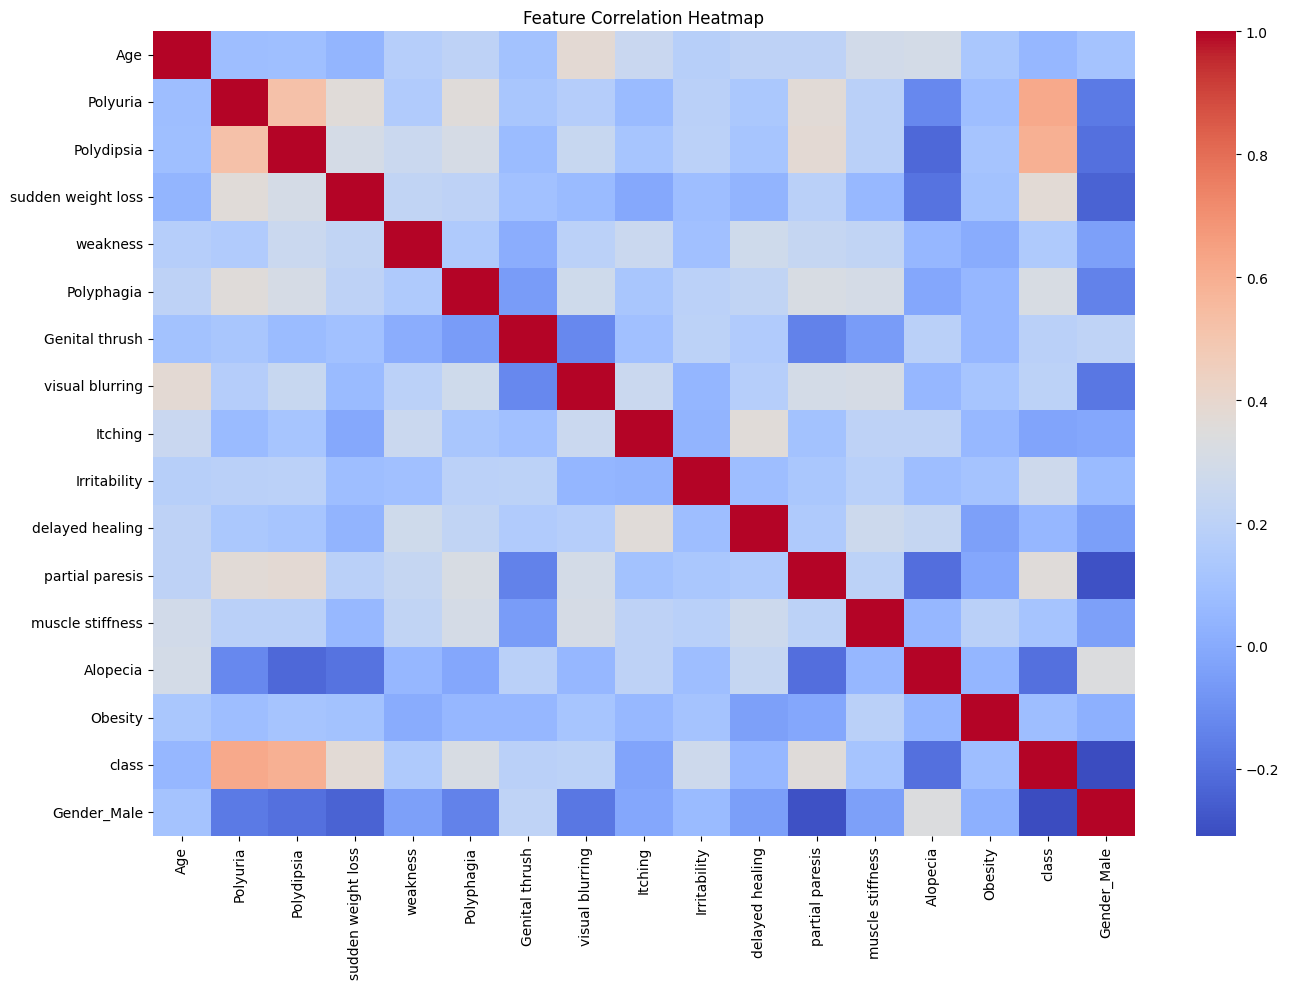

In [16]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    df_encoded.corr(),
    cmap="coolwarm",
    annot=False
)

plt.title("Feature Correlation Heatmap")
plt.tight_layout()

plt.show()

In [17]:
import joblib

# Save trained model
joblib.dump(model, "diabetes_risk_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [18]:
# Create a sample patient
sample = X_test.iloc[[0]]

# Predict
sample_prediction = model.predict(sample)[0]

# Get prediction probability
sample_probability = model.predict_proba(sample)[0]

if sample_prediction == 1:
    print("Predicted Class: Positive")
else:
    print("Predicted Class: Negative")

print(
    "Positive-class model probability:",
    round(sample_probability[1] * 100, 2),
    "%"
)

Predicted Class: Negative
Positive-class model probability: 27.11 %


In [19]:
import os
import shutil

# Create project folder
project = "Diabetes_Analytics_Project"

os.makedirs(project, exist_ok=True)
os.makedirs(f"{project}/visualizations", exist_ok=True)
os.makedirs(f"{project}/model", exist_ok=True)
os.makedirs(f"{project}/results", exist_ok=True)
os.makedirs(f"{project}/dataset", exist_ok=True)

# Save dataset
df_clean.to_csv(
    f"{project}/dataset/diabetes_dataset.csv",
    index=False
)

# Save confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.savefig(
    f"{project}/visualizations/confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close()

# Save performance graph
plt.figure(figsize=(8, 5))

plt.bar(metrics.keys(), metrics.values())
plt.ylim(0, 1)
plt.title("Model Performance Evaluation")
plt.ylabel("Score")

plt.savefig(
    f"{project}/visualizations/performance_metrics.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close()

# Save symptom graph
symptom_counts.sort_values().plot(kind="barh", figsize=(8, 5))

plt.title("Reported Symptoms Distribution")
plt.tight_layout()

plt.savefig(
    f"{project}/visualizations/symptoms.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close()

# Save age distribution graph
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_clean,
    x="Age",
    hue="class",
    bins=15
)

plt.title("Age Distribution")

plt.savefig(
    f"{project}/visualizations/age_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close()

# Save model
joblib.dump(
    model,
    f"{project}/model/diabetes_risk_model.pkl"
)

# Save evaluation results
results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score"],
    "Score": [accuracy, precision, recall, f1]
})

results.to_csv(
    f"{project}/results/model_performance.csv",
    index=False
)

# Generate report
report = f"""
DISEASE PREDICTION AND PERFORMANCE ANALYSIS
USING MACHINE LEARNING

STUDENT PROJECT

OBJECTIVE:
To analyze diabetes risk data and develop a machine
learning classification model using Logistic Regression.

DATASET:
Early Stage Diabetes Risk Prediction Dataset

Number of records analyzed: {len(df_clean)}
Number of features: {X.shape[1]}

ALGORITHM:
Logistic Regression

TRAINING:
80 percent

TESTING:
20 percent

CONFUSION MATRIX:
True Negative: {tn}
False Positive: {fp}
False Negative: {fn}
True Positive: {tp}

PERFORMANCE:
Accuracy: {accuracy*100:.2f}%
Precision: {precision*100:.2f}%
Recall: {recall*100:.2f}%
F1-Score: {f1*100:.2f}%

CONCLUSION:
The project demonstrates data preprocessing,
exploratory analysis, machine learning classification
and performance evaluation.

LIMITATIONS:
This dataset represents a limited population.
The model is educational and not intended
for real-world medical diagnosis.
"""

with open(f"{project}/project_report.txt", "w") as f:
    f.write(report)

# README file
readme = """
# Disease Prediction and Performance Analysis

## Objective
Analyze diabetes risk data using Machine Learning.

## Dataset
Early Stage Diabetes Risk Prediction Dataset.

## Algorithm
Logistic Regression.

## Tools
Python, Google Colab, Pandas, Seaborn,
Matplotlib and Scikit-learn.

## Evaluation Metrics
Accuracy, Precision, Recall, F1-Score
and Confusion Matrix.

## Visualizations
- Confusion Matrix
- Performance Metrics
- Symptoms Distribution
- Age Distribution

## Disclaimer
Educational use only, not a diagnostic tool.
"""

with open(f"{project}/README.md", "w") as f:
    f.write(readme)

# Create ZIP
shutil.make_archive(
    project,
    "zip",
    project
)

print("Your project folder is ready!")

Your project folder is ready!


In [20]:
from google.colab import files

files.download("Diabetes_Analytics_Project.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>